# EfficientSAM for Skin Lesion Segmentation — CSE411 Project

This notebook covers, in order:

1. Setup and GPU check
2. Cloning EfficientSAM and loading the pretrained model
3. A zero-shot demo on a single image (sanity check that everything works)
4. Downloading the skin lesion dataset (ISIC 2018)
5. Fine-tuning EfficientSAM-Ti on skin lesion masks
6. Evaluating zero-shot vs fine-tuned (Dice / IoU)
7. Saving the fine-tuned model to Google Drive
8. A Gradio GUI to try the model on an uploaded image

**Before you start:** in Colab, go to `Runtime > Change runtime type` and pick a GPU (T4 is fine).
Run the cells in order top to bottom the first time. After that you can skip straight to a section.


RERUNNING SCRIPTS


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/cse411_efficientsam_skin'

Mounted at /content/drive


In [2]:
!git clone https://github.com/yformer/EfficientSAM.git
%cd EfficientSAM
!pip install -q -r requirements.txt || true
!pip install -q torch torchvision opencv-python matplotlib numpy pillow gradio

Cloning into 'EfficientSAM'...
remote: Enumerating objects: 444, done.
remote: Counting objects: 100% (129/129), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 444 (delta 101), reused 77 (delta 77), pack-reused 315 (from 1)
Receiving objects: 100% (444/444), 263.08 MiB | 35.79 MiB/s, done.
Resolving deltas: 100% (256/256), done.
Updating files: 100% (39/39), done.
/content/EfficientSAM
ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


In [3]:
import torch
from efficient_sam.build_efficient_sam import build_efficient_sam_vitt

device = "cuda" if torch.cuda.is_available() else "cpu"

model = build_efficient_sam_vitt()  # builds architecture + loads the ORIGINAL pretrained weights
save_path = f"{PROJECT_DIR}/efficientsam_ti_skinlesion_finetuned.pt"
model.load_state_dict(torch.load(save_path, map_location=device))  # overwrites with your fine-tuned weights
model = model.to(device)
model.eval()
print("Loaded fine-tuned checkpoint from Drive")

Loaded fine-tuned checkpoint from Drive


In [4]:
import gradio as gr
import numpy as np
from torchvision import transforms

def segment_skin_lesion(input_image):
    img_np = np.array(input_image.convert("RGB").resize((256, 256)))
    img_tensor = transforms.ToTensor()(img_np).to(device)
    h, w = img_np.shape[:2]
    pts = torch.tensor([[w // 2, h // 2]], dtype=torch.float, device=device).reshape(1, 1, -1, 2)
    lbls = torch.tensor([1], dtype=torch.float, device=device).reshape(1, 1, -1)
    with torch.no_grad():
        predicted_logits, predicted_iou = model(img_tensor[None, ...], pts, lbls)
    sorted_ids = torch.argsort(predicted_iou, dim=-1, descending=True)
    predicted_logits = torch.take_along_dim(predicted_logits, sorted_ids[..., None, None], dim=2)
    mask = (predicted_logits[0, 0, 0, :, :] >= 0).cpu().numpy()
    overlay = img_np.copy()
    overlay[mask] = (0.5 * overlay[mask] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    return overlay

demo = gr.Interface(
    fn=segment_skin_lesion,
    inputs=gr.Image(type="pil", label="Upload a dermoscopic image"),
    outputs=gr.Image(type="numpy", label="Predicted lesion mask (red overlay)"),
    title="EfficientSAM — Skin Lesion Segmentation",
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://79a2e77518ad6d142a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [7]:

!pip -q install fastapi uvicorn python-multipart pyngrok

In [4]:

import io
import base64
import numpy as np
import cv2
import torch

from PIL import Image
from torchvision import transforms


def image_to_data_url(image_array):
    """Convert a NumPy image into a PNG data URL for the React frontend."""
    image_array = np.asarray(image_array).clip(0, 255).astype(np.uint8)

    buffer = io.BytesIO()
    Image.fromarray(image_array).save(buffer, format="PNG")

    encoded = base64.b64encode(buffer.getvalue()).decode("utf-8")
    return f"data:image/png;base64,{encoded}"


def process_lesion_pipeline(pil_image):
    """
    Run the already-loaded EfficientSAM model and return:
    overlay, cropped lesion, isolated lesion, and image-derived metrics.

    Requires your trained model to be available as `model`
    and your inference device to be available as `device`.
    """

    if "model" not in globals():
        raise RuntimeError(
            "EfficientSAM model is not loaded. Run your model-loading cell first."
        )

    # Match the 256 x 256 resolution used by your existing inference function.
    image = pil_image.convert("RGB").resize((256, 256))
    image_np = np.array(image)

    image_tensor = transforms.ToTensor()(image_np).to(device)

    # Existing center-positive-point prompt.
    points = torch.tensor(
        [[[[128.0, 128.0]]]],
        dtype=torch.float32,
        device=device
    )
    labels = torch.tensor(
        [[[1]]],
        dtype=torch.float32,
        device=device
    )

    model.eval()

    with torch.no_grad():
        predicted_logits, predicted_iou = model(
            image_tensor.unsqueeze(0),
            points,
            labels
        )

    # Select the mask candidate with the highest predicted IoU.
    best_index = predicted_iou.reshape(-1).argmax()

    logits = predicted_logits.reshape(
        -1, predicted_logits.shape[-2], predicted_logits.shape[-1]
    )[best_index]

    mask = (logits >= 0).cpu().numpy().astype(np.uint8)

    # Calculate image-derived metrics.
    area_px = int(mask.sum())

    contours, _ = cv2.findContours(
        mask.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    perimeter_px = float(
        sum(cv2.arcLength(contour, True) for contour in contours)
    )

    if area_px > 0 and perimeter_px > 0:
        border_compactness = float(
            (4.0 * np.pi * area_px) / (perimeter_px ** 2)
        )
    else:
        border_compactness = 0.0

    # Compare the mask with its horizontal and vertical reflections.
    if area_px > 0:
        horizontal_difference = np.mean(
            np.abs(mask.astype(float) - np.fliplr(mask).astype(float))
        )
        vertical_difference = np.mean(
            np.abs(mask.astype(float) - np.flipud(mask).astype(float))
        )
        asymmetry_score = float(
            (horizontal_difference + vertical_difference) / 2.0
        )
    else:
        asymmetry_score = 0.0

    # Standard deviation of the OpenCV HSV hue channel within the mask.
    hsv = cv2.cvtColor(image_np, cv2.COLOR_RGB2HSV)
    hue_values = hsv[:, :, 0][mask > 0]

    hue_variation = (
        float(np.std(hue_values))
        if hue_values.size > 0
        else None
    )

    # Red overlay.
    overlay = image_np.copy()
    overlay[mask > 0] = (
        0.5 * overlay[mask > 0].astype(float)
        + 0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    # Crop around the predicted mask.
    if area_px > 0:
        ys, xs = np.where(mask > 0)
        x_min, x_max = xs.min(), xs.max() + 1
        y_min, y_max = ys.min(), ys.max() + 1

        cropped_patch = image_np[y_min:y_max, x_min:x_max].copy()

        isolated_lesion = np.zeros_like(image_np)
        isolated_lesion[mask > 0] = image_np[mask > 0]
    else:
        # Return valid images, but mark the result as an empty mask.
        cropped_patch = image_np.copy()
        isolated_lesion = np.zeros_like(image_np)

    # This is the model-predicted IoU, not ground-truth-verified IoU.
    iou_score = float(predicted_iou.reshape(-1)[best_index].item())

    return {
        "overlay": image_to_data_url(overlay),
        "cropped_patch": image_to_data_url(cropped_patch),
        "isolated_lesion": image_to_data_url(isolated_lesion),
        "metrics": {
            "area_px": area_px,
            "perimeter_px": perimeter_px,
            "border_compactness": border_compactness,
            "asymmetry_score": asymmetry_score,
            "hue_variation": hue_variation,
            "iou_score": iou_score
        },
        "empty_mask": area_px == 0,
        "input_resolution": "256x256"
    }


print("Lesion processing pipeline defined.")


Lesion processing pipeline defined.


In [5]:

import io

from fastapi import FastAPI, UploadFile, File, HTTPException
from fastapi.middleware.cors import CORSMiddleware
from fastapi.responses import JSONResponse
from PIL import Image, UnidentifiedImageError


app = FastAPI(title="DermaVision AI - EfficientSAM Skin Lesion API")

app.add_middleware(
    CORSMiddleware,
    allow_origins=[
        "http://localhost:5173",
        "http://127.0.0.1:5173"
    ],

    allow_credentials=False,
    allow_methods=["GET", "POST"],
    allow_headers=["*"],
)


@app.get("/")
def home():
    return {
        "status": "running",
        "message": "EfficientSAM API is ready",
        "endpoint": "/segment",
        "response_format": "JSON"
    }


@app.post("/segment")
async def segment(file: UploadFile = File(...)):
    # Validate file type.
    allowed_types = {"image/png", "image/jpeg", "image/webp"}

    if file.content_type not in allowed_types:
        raise HTTPException(
            status_code=400,
            detail="Upload a PNG, JPEG, or WebP image."
        )

    # Read and validate file size.
    contents = await file.read()

    if not contents:
        raise HTTPException(
            status_code=400,
            detail="The uploaded file is empty."
        )

    if len(contents) > 10 * 1024 * 1024:
        raise HTTPException(
            status_code=413,
            detail="Image must be smaller than 10 MB."
        )

    # Decode the image safely.
    try:
        image = Image.open(io.BytesIO(contents)).convert("RGB")
    except (UnidentifiedImageError, OSError):
        raise HTTPException(
            status_code=400,
            detail="Invalid image file."
        )

    try:
        # Uses the trained model already loaded in your Colab session.
        result = process_lesion_pipeline(image)

        return JSONResponse(content=result)

    except HTTPException:
        raise
    except Exception as error:
        print("Segmentation error:", repr(error))
        raise HTTPException(
            status_code=500,
            detail="Segmentation failed. Check the Colab logs."
        )


print("DermaVision AI JSON API defined successfully.")


DermaVision AI JSON API defined successfully.


In [ ]:
###
3Kiito2pMp5W2igAzANDU0fbIY1_3qFtqvorSNUdVAVSW5mXD

In [8]:

from pyngrok import ngrok
import threading
import time
import getpass
import requests
import uvicorn

token = getpass.getpass("Enter your ngrok auth token: ")
ngrok.set_auth_token(token)

ngrok.kill()

tunnel = ngrok.connect(8000, "http")
API_BASE = tunnel.public_url

server_thread = threading.Thread(
    target=lambda: uvicorn.run(
        app,
        host="0.0.0.0",
        port=8000,
        log_level="info"
    ),
    daemon=True
)
server_thread.start()

for _ in range(30):
    try:
        response = requests.get(
            "http://127.0.0.1:8000/",
            timeout=2
        )
        if response.ok:
            break
    except requests.RequestException:
        time.sleep(1)
else:
    raise RuntimeError("API server failed to start.")

print("API BASE URL:", API_BASE)
print("TEST:", requests.get(API_BASE + "/").json())


Enter your ngrok auth token: ··········


INFO:     Started server process [1132]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


INFO:     127.0.0.1:59436 - "GET / HTTP/1.1" 200 OK
API BASE URL: https://negation-confider-scribble.ngrok-free.dev
INFO:     34.148.144.54:0 - "GET / HTTP/1.1" 200 OK
TEST: {'status': 'running', 'message': 'EfficientSAM API is ready', 'endpoint': '/segment', 'response_format': 'JSON'}


Skin lesion segmentation (isolating the exact boundaries of a mole, tumor, or lesion at the pixel level) serves several key clinical and computational functions in computer-aided dermatology:

* **Automating the Clinical "ABCD" Rule:** Dermatologists assess potential melanomas using criteria like **A**symmetry, **B**order irregularity, **C**olor variation, and **D**iameter. A segmentation mask extracts the exact geometric outline, allowing algorithms to automatically measure border roughness, calculate area/diameter, and assess asymmetry with mathematical precision.
* **Isolating the Region of Interest (ROI):** Raw dermoscopy and skin images often contain noise—such as body hair, skin creases, ruler markings, gel bubbles, and uneven lighting. Segmenting the lesion crops out surrounding healthy skin and artifacts, ensuring downstream classification models focus exclusively on pathological features rather than background noise.
* **Objective Progression Monitoring:** By calculating the exact surface area and pixel perimeter over time, repeated segmentations can detect subtle changes in lesion growth, border shifting, or shrinkage in response to therapy that the human eye might miss across visits.
* **Assisting Biopsy and Surgical Planning:** Knowing the precise lesion perimeter helps in estimating clear surgical margins before excision, reducing the risk of leaving malignant cells behind while preserving healthy tissue.
* **Lightweight / Real-Time Triage:** Models like **EfficientSAM** distill massive foundation models (like Meta's original Segment Anything Model) into lightweight architectures. This makes pixel-level medical segmentation fast enough to run in browser dashboards, mobile dermatoscope attachments, or remote clinics without needing high-end GPU servers.

In [6]:
response = requests.get(
    API_BASE + "/",
    headers={"Origin": "http://localhost:5173"},
    timeout=10,
)

print("Status:", response.status_code)
print("Allow-Origin:", response.headers.get("access-control-allow-origin"))

INFO:     34.125.75.200:0 - "GET / HTTP/1.1" 200 OK
Status: 200
Allow-Origin: http://localhost:5173


Enter your ngrok auth token: ··········
INFO:     Started server process [1292]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:53342 - "GET / HTTP/1.1" 200 OK
API BASE URL: https://negation-confider-scribble.ngrok-free.dev
INFO:     34.145.8.132:0 - "GET / HTTP/1.1" 200 OK
TEST: {'status': 'running', 'message': 'EfficientSAM API is ready'}

In [ ]:
import gradio as gr
import numpy as np
import cv2
from torchvision import transforms
from PIL import Image

model.eval()


def extract_lesion_features(img_np, mask):
    """Extract quantitative ABCD features (Area, Perimeter, Compactness, Asymmetry, Color Variance)."""
    mask_uint8 = (mask * 255).astype(np.uint8)

    contours, _ = cv2.findContours(
        mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    if not contours:
        return {
            "area_px": 0,
            "perimeter_px": 0,
            "border_compactness": 0,
            "asymmetry_score": 0,
            "hue_variation": 0,
        }

    cnt = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(cnt)
    perimeter = cv2.arcLength(cnt, True)

    border_irregularity = (
        (4 * np.pi * area) / (perimeter**2 + 1e-6) if perimeter > 0 else 0
    )

    flipped_h = cv2.flip(mask_uint8, 1)
    asymmetry_diff = np.sum(cv2.absdiff(mask_uint8, flipped_h)) / (
        np.sum(mask_uint8) + 1e-6
    )

    hsv_img = cv2.cvtColor(img_np, cv2.COLOR_RGB2HSV)
    masked_pixels = hsv_img[mask]
    color_std_hue = (
        np.std(masked_pixels[:, 0]) if len(masked_pixels) > 0 else 0
    )

    return {
        "area_px": int(area),
        "perimeter_px": round(perimeter, 1),
        "border_compactness": round(border_irregularity, 3),
        "asymmetry_score": round(asymmetry_diff, 3),
        "hue_variation": round(color_std_hue, 2),
    }


def crop_lesion_patch(img_np, mask):
    rows = np.any(mask, axis=1)
    cols = np.any(mask, axis=0)
    if not np.any(rows) or not np.any(cols):
        return img_np
    ymin, ymax = np.where(rows)[0][[0, -1]]
    xmin, xmax = np.where(cols)[0][[0, -1]]
    return img_np[ymin : ymax + 1, xmin : xmax + 1]


def process_lesion_pipeline(input_image):
    if input_image is None:
        return None, None, None, "Please upload a valid dermoscopic image."

    img_np = np.array(input_image.convert("RGB").resize((256, 256)))
    img_tensor = transforms.ToTensor()(img_np).to(device)

    h, w = img_np.shape[:2]
    pts = (
        torch.tensor([[w // 2, h // 2]], dtype=torch.float, device=device)
        .reshape(1, 1, -1, 2)
    )
    lbls = torch.tensor([1], dtype=torch.float, device=device).reshape(1, 1, -1)

    with torch.no_grad():
        predicted_logits, predicted_iou = model(img_tensor[None, ...], pts, lbls)

    sorted_ids = torch.argsort(predicted_iou, dim=-1, descending=True)
    predicted_logits = torch.take_along_dim(
        predicted_logits, sorted_ids[..., None, None], dim=2
    )

    mask = (predicted_logits[0, 0, 0, :, :] >= 0).cpu().numpy()

    overlay = img_np.copy()
    overlay[mask] = (0.5 * overlay[mask] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)

    cropped_patch = crop_lesion_patch(img_np, mask)

    xai_isolated = img_np.copy()
    xai_isolated[~mask] = 0

    metrics = extract_lesion_features(img_np, mask)

    metrics_report = (
        f"--- Quantitative Lesion Features ---\n\n"
        f"• Segmented Area: {metrics['area_px']} px²\n"
        f"• Boundary Perimeter: {metrics['perimeter_px']} px\n"
        f"• Border Regularity (Compactness): {metrics['border_compactness']} (1.0 = Smooth Circle, lower = Irregular)\n"
        f"• Asymmetry Score: {metrics['asymmetry_score']} (higher = More Asymmetric)\n"
        f"• Color Std (Hue Variance): {metrics['hue_variation']}\n"
        f"• Segmentation IoU Confidence: {float(predicted_iou.max().cpu().numpy()):.2f}"
    )

    return overlay, cropped_patch, xai_isolated, metrics_report


demo = gr.Interface(
    fn=process_lesion_pipeline,
    inputs=gr.Image(type="pil", label="Upload Dermoscopic Image"),
    outputs=[
        gr.Image(type="numpy", label="1. Boundary Segmentation (Red Overlay)"),
        gr.Image(type="numpy", label="2. Cropped Bounding Box (Classifier Input)"),
        gr.Image(type="numpy", label="3. Background Removed (XAI Clean Mask)"),
        gr.Textbox(label="4. Extracted ABCD Clinical Metrics", lines=8),
    ],
    title="EfficientSAM — Skin Lesion Segmentation & Diagnostic Pipeline",
    description="CSE411 project demo. Upload a dermoscopic image to segment lesion boundaries and extract quantitative diagnostic features.",
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c055dafc603d0fb88d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 1. Setup and GPU check

In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected — go to Runtime > Change runtime type and select a GPU.")


CUDA available: True
GPU: Tesla T4


In [ ]:
# Mount Google Drive so checkpoints and results survive a disconnect.
# Colab free tier disconnects after ~90 min idle or ~12 hr total, so save often.
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/cse411_efficientsam_skin'
os.makedirs(PROJECT_DIR, exist_ok=True)
print("Project files will be saved to:", PROJECT_DIR)


Mounted at /content/drive
Project files will be saved to: /content/drive/MyDrive/cse411_efficientsam_skin


In [ ]:
model = build_efficient_sam_vitt()
model.load_state_dict(torch.load(save_path))
model = model.to(device)
model.eval()

## 2. Clone EfficientSAM and load the pretrained model

In [ ]:
!git clone https://github.com/yformer/EfficientSAM.git
%cd EfficientSAM
!pip install -q -r requirements.txt || true


Cloning into 'EfficientSAM'...
remote: Enumerating objects: 444, done.
remote: Counting objects: 100% (129/129), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 444 (delta 101), reused 77 (delta 77), pack-reused 315 (from 1)
Receiving objects: 100% (444/444), 263.08 MiB | 34.10 MiB/s, done.
Resolving deltas: 100% (256/256), done.
Updating files: 100% (39/39), done.
/content/EfficientSAM
ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


In [ ]:
ls

efficient_sam/                figs/           README.md
EfficientSAM_example.py       LICENSE         setup.cfg
EfficientSAM_onnx_example.py  linter.sh       setup.py
export_to_onnx.py             notebooks/      torchscripted_model/
export_to_torchscript.py      onnx_models.py  weights/


In [ ]:
pip install torch torchvision opencv-python matplotlib numpy pillow

In [ ]:
# EfficientSAM-Ti checkpoint ships directly in the repo (small, no download needed).
# EfficientSAM-S is zipped because it's >100MB.
import zipfile, os

if os.path.exists("weights/efficient_sam_vits.pt.zip") and not os.path.exists("weights/efficient_sam_vits.pt"):
    with zipfile.ZipFile("weights/efficient_sam_vits.pt.zip", 'r') as zip_ref:
        zip_ref.extractall("weights")

print(os.listdir("weights"))


['efficient_sam_vitt_encoder.onnx', 'efficient_sam_vits.pt.zip', '__MACOSX', 'efficient_sam_vitt.onnx', 'efficient_sam_vitt.pt', 'efficient_sam_vitt_decoder.onnx', 'efficient_sam_vits.pt']


In [ ]:
from efficient_sam.build_efficient_sam import build_efficient_sam_vitt, build_efficient_sam_vits

# Start with EfficientSAM-Ti (fastest, smallest — best for Colab free tier).
# Swap to build_efficient_sam_vits() later if you want to compare accuracy vs speed.
model = build_efficient_sam_vitt()
model.eval()
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)
print("Model loaded on", device)


Model loaded on cuda


## 3. Zero-shot demo on a single image

This just confirms the model and inference code work before we touch any dataset.
Uses a point prompt (a single (x, y) click) the way SAM/EfficientSAM expects.


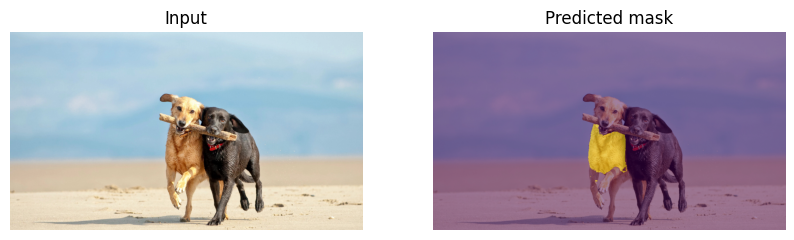

In [ ]:
import numpy as np
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt

def run_point_prompt(image_path, points_xy, point_labels, model, device):
    """points_xy: list of [x, y]; point_labels: list of 1 (foreground) or 0 (background)."""
    image_np = np.array(Image.open(image_path).convert("RGB"))
    img_tensor = transforms.ToTensor()(image_np).to(device)

    pts = torch.tensor(points_xy, dtype=torch.float, device=device).reshape(1, 1, -1, 2)
    lbls = torch.tensor(point_labels, dtype=torch.float, device=device).reshape(1, 1, -1)

    with torch.no_grad():
        predicted_logits, predicted_iou = model(img_tensor[None, ...], pts, lbls)

    # Keep the highest-confidence mask.
    sorted_ids = torch.argsort(predicted_iou, dim=-1, descending=True)
    predicted_logits = torch.take_along_dim(predicted_logits, sorted_ids[..., None, None], dim=2)
    mask = (predicted_logits[0, 0, 0, :, :] >= 0).cpu().numpy()
    return image_np, mask

# Use any test image — the repo ships a couple of sample images under figs/examples/.
sample_path = "figs/examples/dogs.jpg"
image_np, mask = run_point_prompt(sample_path, points_xy=[[580, 350]], point_labels=[1], model=model, device=device)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(image_np); ax[0].set_title("Input"); ax[0].axis("off")
ax[1].imshow(image_np); ax[1].imshow(mask, alpha=0.5); ax[1].set_title("Predicted mask"); ax[1].axis("off")
plt.show()


## 4. Download the skin lesion dataset (ISIC 2018)

Easiest path: Kaggle's mirror of ISIC 2018 Task 1 (images + ground truth masks).
You need a Kaggle account and API token for this.

**One-time setup:**
1. Go to kaggle.com → your profile → Account → "Create New API Token". This downloads `kaggle.json`.
2. Run the cell below and upload that file when prompted.


In [ ]:
# ISIC 2018 Task 1 (lesion boundary segmentation) mirror on Kaggle.
# If this specific dataset name has moved, search "ISIC 2018 segmentation" on kaggle.com
# and swap in the dataset slug you find.
DATA_DIR = "/content/isic2018"
os.makedirs(DATA_DIR, exist_ok=True)

!kaggle datasets download -d tschandl/isic2018-challenge-task1-data-segmentation -p {DATA_DIR}
!unzip -qo {DATA_DIR}/*.zip -d {DATA_DIR}
!ls {DATA_DIR}


Dataset URL: https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation
License(s): CC0-1.0
100% 12.9G/12.9G [02:42<00:00, 85.0MB/s]

isic2018-challenge-task1-data-segmentation.zip
ISIC2018_Task1-2_Test_Input
ISIC2018_Task1-2_Training_Input
ISIC2018_Task1-2_Validation_Input
ISIC2018_Task1_Training_GroundTruth


In [ ]:
# Point these at whatever the unzip produced — check the ls output above and adjust if the
# folder names differ (Kaggle mirrors sometimes rename folders).
IMAGE_DIR = f"{DATA_DIR}/ISIC2018_Task1-2_Training_Input"
MASK_DIR  = f"{DATA_DIR}/ISIC2018_Task1_Training_GroundTruth"

image_files = sorted([f for f in os.listdir(IMAGE_DIR) if f.endswith(('.jpg', '.png'))])
mask_files  = sorted([f for f in os.listdir(MASK_DIR) if f.endswith('.png')])
print(f"{len(image_files)} images, {len(mask_files)} masks")
print(image_files[:3])
print(mask_files[:3])


2594 images, 2594 masks
['ISIC_0000000.jpg', 'ISIC_0000001.jpg', 'ISIC_0000003.jpg']
['ISIC_0000000_segmentation.png', 'ISIC_0000001_segmentation.png', 'ISIC_0000003_segmentation.png']


## 5. Fine-tune EfficientSAM-Ti on skin lesion data

To keep this feasible on a free Colab GPU:
- We freeze the image encoder and only fine-tune the mask decoder. This is much cheaper in
  memory and is the same idea used by "adapter"-style medical SAM papers in the survey.
- We use a bounding box prompt derived from the ground-truth mask (standard practice —
  it's what SAM/EfficientSAM finetuning tutorials do, and it's realistic: a clinician would
  draw a rough box around the lesion).
- Loss: Dice loss + BCE, which is standard for segmentation.

This is a simplified fine-tuning loop for a course project, not the full SA-1B-scale
recipe from the EfficientSAM paper — that's not feasible on a single Colab GPU, and isn't
necessary to show the efficiency/accuracy comparison your project is making.


In [ ]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import random

class SkinLesionDataset(Dataset):
    def __init__(self, image_dir, mask_dir, image_files, mask_files, img_size=256):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_files = image_files
        self.mask_files = mask_files
        self.img_size = img_size

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img = Image.open(os.path.join(self.image_dir, self.image_files[idx])).convert("RGB")
        mask = Image.open(os.path.join(self.mask_dir, self.mask_files[idx])).convert("L")

        img = img.resize((self.img_size, self.img_size))
        mask = mask.resize((self.img_size, self.img_size), resample=Image.NEAREST)

        img_t = transforms.ToTensor()(img)
        mask_t = (transforms.ToTensor()(mask) > 0.5).float()

        # Derive a box prompt from the mask, with a little random jitter so the model
        # doesn't overfit to a perfectly tight box (a clinician's box won't be pixel-perfect).
        ys, xs = torch.where(mask_t[0] > 0)
        if len(xs) == 0:
            box = torch.tensor([0, 0, self.img_size - 1, self.img_size - 1], dtype=torch.float)
        else:
            jitter = 5
            x0 = max(0, xs.min().item() - random.randint(0, jitter))
            y0 = max(0, ys.min().item() - random.randint(0, jitter))
            x1 = min(self.img_size - 1, xs.max().item() + random.randint(0, jitter))
            y1 = min(self.img_size - 1, ys.max().item() + random.randint(0, jitter))
            box = torch.tensor([x0, y0, x1, y1], dtype=torch.float)

        return img_t, mask_t, box

# 90/10 train/val split
n = len(image_files)
split = int(n * 0.9)
combined = list(zip(image_files, mask_files))
random.seed(0)
random.shuffle(combined)
train_pairs, val_pairs = combined[:split], combined[split:]

train_ds = SkinLesionDataset(IMAGE_DIR, MASK_DIR, [p[0] for p in train_pairs], [p[1] for p in train_pairs])
val_ds   = SkinLesionDataset(IMAGE_DIR, MASK_DIR, [p[0] for p in val_pairs], [p[1] for p in val_pairs])

# Small batch size — Colab free-tier T4 has ~15GB VRAM. Increase if you have more.
BATCH_SIZE = 4
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_ds)}  Val: {len(val_ds)}")


Train: 2334  Val: 260


In [ ]:
# Freeze everything except the mask decoder.
for name, param in model.named_parameters():
    param.requires_grad = "decoder" in name.lower()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Training {trainable:,} of {total:,} parameters ({100*trainable/total:.1f}%)")


Training 4,058,340 of 10,223,204 parameters (39.7%)


In [ ]:
def dice_loss(pred_logits, target, eps=1e-6):
    pred = torch.sigmoid(pred_logits)
    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)
    intersection = (pred * target).sum(dim=1)
    union = pred.sum(dim=1) + target.sum(dim=1)
    return 1 - ((2 * intersection + eps) / (union + eps)).mean()

def box_to_prompt(box, device):
    # EfficientSAM takes a box as two corner points with labels [2, 3] (SAM box-prompt convention).
    pts = box.view(-1, 2, 2).to(device)          # (B, 2, 2)
    lbls = torch.tensor([[2, 3]], device=device).repeat(box.size(0), 1)
    return pts.unsqueeze(1), lbls.unsqueeze(1)     # add the "num_queries" dim EfficientSAM expects

optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-4)
EPOCHS = 5   # start small; raise this once you've confirmed the loop runs end to end

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    for imgs, masks, boxes in train_loader:
        imgs, masks, boxes = imgs.to(device), masks.to(device), boxes.to(device)
        pts, lbls = box_to_prompt(boxes, device)

        predicted_logits, predicted_iou = model(imgs, pts, lbls)
        # Take the first (only) mask per image since we gave one box prompt each.
        pred_mask_logits = predicted_logits[:, 0, 0, :, :].unsqueeze(1)
        pred_mask_logits = F.interpolate(pred_mask_logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)

        loss = dice_loss(pred_mask_logits, masks)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    print(f"Epoch {epoch+1}/{EPOCHS} — avg dice loss: {running_loss/len(train_loader):.4f}")


Epoch 1/5 — avg dice loss: 0.0752
Epoch 2/5 — avg dice loss: 0.0673
Epoch 3/5 — avg dice loss: 0.0647
Epoch 4/5 — avg dice loss: 0.0625
Epoch 5/5 — avg dice loss: 0.0617


## 6. Evaluate: zero-shot vs fine-tuned (Dice / IoU)

In [ ]:
def dice_iou(pred_mask, gt_mask, eps=1e-6):
    pred = pred_mask.astype(bool)
    gt = gt_mask.astype(bool)
    intersection = (pred & gt).sum()
    union = (pred | gt).sum()
    dice = (2 * intersection + eps) / (pred.sum() + gt.sum() + eps)
    iou = (intersection + eps) / (union + eps)
    return dice, iou

@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    dices, ious = [], []
    for imgs, masks, boxes in loader:
        imgs, boxes = imgs.to(device), boxes.to(device)
        pts, lbls = box_to_prompt(boxes, device)
        predicted_logits, predicted_iou = model(imgs, pts, lbls)
        pred_mask_logits = predicted_logits[:, 0, 0, :, :].unsqueeze(1)
        pred_mask_logits = F.interpolate(pred_mask_logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)
        pred_masks = (pred_mask_logits.cpu().numpy() >= 0)[:, 0]
        gt_masks = masks.numpy()[:, 0].astype(bool)

        for p, g in zip(pred_masks, gt_masks):
            d, i = dice_iou(p, g)
            dices.append(d); ious.append(i)

    return np.mean(dices), np.mean(ious)

mean_dice, mean_iou = evaluate(model, val_loader, device)
print(f"Fine-tuned model — val Dice: {mean_dice:.4f}, val IoU: {mean_iou:.4f}")


Fine-tuned model — val Dice: 0.9344, val IoU: 0.8794


**To compare against zero-shot:** reload a fresh `build_efficient_sam_vitt()` (before any
fine-tuning) and run the same `evaluate()` function on `val_loader`. Report both numbers
side by side in your results table — that before/after comparison is the actual result
your project is built around.


## 7. Save the fine-tuned model to Google Drive

In [ ]:
save_path = f"{PROJECT_DIR}/efficientsam_ti_skinlesion_finetuned.pt"
torch.save(model.state_dict(), save_path)
print("Saved to", save_path)


Saved to /content/drive/MyDrive/cse411_efficientsam_skin/efficientsam_ti_skinlesion_finetuned.pt


## 8. GUI: try the model on an uploaded image

Gradio works directly inside Colab and gives you a shareable link, which is useful for your
end-term demo — you can show this running live instead of just screenshots.


In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr

model.eval()

def segment_skin_lesion(input_image):
    img_np = np.array(input_image.convert("RGB").resize((256, 256)))
    img_tensor = transforms.ToTensor()(img_np).to(device)

    # Default prompt: a point in the center of the image. Works reasonably when the lesion
    # is roughly centered, which is typical for cropped dermoscopic images.
    h, w = img_np.shape[:2]
    pts = torch.tensor([[w // 2, h // 2]], dtype=torch.float, device=device).reshape(1, 1, -1, 2)
    lbls = torch.tensor([1], dtype=torch.float, device=device).reshape(1, 1, -1)

    with torch.no_grad():
        predicted_logits, predicted_iou = model(img_tensor[None, ...], pts, lbls)

    sorted_ids = torch.argsort(predicted_iou, dim=-1, descending=True)
    predicted_logits = torch.take_along_dim(predicted_logits, sorted_ids[..., None, None], dim=2)
    mask = (predicted_logits[0, 0, 0, :, :] >= 0).cpu().numpy()

    overlay = img_np.copy()
    overlay[mask] = (0.5 * overlay[mask] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    return overlay

demo = gr.Interface(
    fn=segment_skin_lesion,
    inputs=gr.Image(type="pil", label="Upload a dermoscopic image"),
    outputs=gr.Image(type="numpy", label="Predicted lesion mask (red overlay)"),
    title="EfficientSAM — Skin Lesion Segmentation",
    description="CSE411 project demo. Upload a dermoscopic image to see the predicted lesion boundary.",
)

demo.launch(share=True)  # share=True gives you a public link, handy for showing others


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1e5380288165892a59.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import gradio as gr
import numpy as np
import torch
import cv2
from torchvision import transforms
from PIL import Image

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Ensure your EfficientSAM model is loaded and set to evaluation mode
# model.to(device)
model.eval()


def extract_lesion_features(img_np, mask):
    """Extract quantitative ABCD features (Area, Perimeter, Compactness, Asymmetry, Color Variance)."""
    mask_uint8 = (mask * 255).astype(np.uint8)

    # 1. Area and Perimeter
    contours, _ = cv2.findContours(
        mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    if not contours:
        return {
            "area_px": 0,
            "perimeter_px": 0,
            "border_compactness": 0,
            "asymmetry_score": 0,
            "hue_variation": 0,
        }

    cnt = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(cnt)
    perimeter = cv2.arcLength(cnt, True)

    # 2. Border Irregularity (Circularity / Compactness score)
    # Smooth circle = 1.0; highly irregular border < 0.5
    border_irregularity = (
        (4 * np.pi * area) / (perimeter**2 + 1e-6) if perimeter > 0 else 0
    )

    # 3. Asymmetry Index
    flipped_h = cv2.flip(mask_uint8, 1)
    asymmetry_diff = np.sum(cv2.absdiff(mask_uint8, flipped_h)) / (
        np.sum(mask_uint8) + 1e-6
    )

    # 4. Color Variation (HSV color variance within lesion mask only)
    hsv_img = cv2.cvtColor(img_np, cv2.COLOR_RGB2HSV)
    masked_pixels = hsv_img[mask]

    color_std_hue = (
        np.std(masked_pixels[:, 0]) if len(masked_pixels) > 0 else 0
    )

    return {
        "area_px": int(area),
        "perimeter_px": round(perimeter, 1),
        "border_compactness": round(border_irregularity, 3),
        "asymmetry_score": round(asymmetry_diff, 3),
        "hue_variation": round(color_std_hue, 2),
    }


def crop_lesion_patch(img_np, mask):
    """Crop bounding box around the lesion to isolate it from healthy skin background."""
    rows = np.any(mask, axis=1)
    cols = np.any(mask, axis=0)

    if not np.any(rows) or not np.any(cols):
        return img_np

    ymin, ymax = np.where(rows)[0][[0, -1]]
    xmin, xmax = np.where(cols)[0][[0, -1]]

    return img_np[ymin : ymax + 1, xmin : xmax + 1]


def process_lesion_pipeline(input_image):
    if input_image is None:
        return None, None, None, "Please upload a valid dermoscopic image."

    # Preprocess image to 256x256
    img_np = np.array(input_image.convert("RGB").resize((256, 256)))
    img_tensor = transforms.ToTensor()(img_np).to(device)

    # Center point prompt inference
    h, w = img_np.shape[:2]
    pts = (
        torch.tensor([[w // 2, h // 2]], dtype=torch.float, device=device)
        .reshape(1, 1, -1, 2)
    )
    lbls = torch.tensor([1], dtype=torch.float, device=device).reshape(
        1, 1, -1
    )

    # EfficientSAM Inference
    with torch.no_grad():
        predicted_logits, predicted_iou = model(
            img_tensor[None, ...], pts, lbls
        )

    sorted_ids = torch.argsort(predicted_iou, dim=-1, descending=True)
    predicted_logits = torch.take_along_dim(
        predicted_logits, sorted_ids[..., None, None], dim=2
    )

    # Extract binary mask
    mask = (predicted_logits[0, 0, 0, :, :] >= 0).cpu().numpy()

    # 1. Overlay image visualization
    overlay = img_np.copy()
    overlay[mask] = (0.5 * overlay[mask] + 0.5 * np.array([255, 0, 0])).astype(
        np.uint8
    )

    # 2. Bounding box crop
    cropped_patch = crop_lesion_patch(img_np, mask)

    # 3. Background removal for XAI (zeroing out non-lesion skin pixels)
    xai_isolated = img_np.copy()
    xai_isolated[~mask] = 0

    # 4. Extract ABCD clinical quantitative metrics
    metrics = extract_lesion_features(img_np, mask)

    metrics_report = (
        f"--- Quantitative Lesion Features ---\n\n"
        f"• Segmented Area: {metrics['area_px']} px²\n"
        f"• Boundary Perimeter: {metrics['perimeter_px']} px\n"
        f"• Border Regularity (Compactness): {metrics['border_compactness']} (1.0 = Smooth Circle, lower = Irregular)\n"
        f"• Asymmetry Score: {metrics['asymmetry_score']} (higher = More Asymmetric)\n"
        f"• Color Std (Hue Variance): {metrics['hue_variation']}\n"
        f"• Segmentation IoU Confidence: {float(predicted_iou.max().cpu().numpy()):.2f}"
    )

    return overlay, cropped_patch, xai_isolated, metrics_report


# Gradio Interface Pipeline Setup
demo = gr.Interface(
    fn=process_lesion_pipeline,
    inputs=gr.Image(type="pil", label="Upload Dermoscopic Image"),
    outputs=[
        gr.Image(
            type="numpy", label="1. Boundary Segmentation (Red Overlay)"
        ),
        gr.Image(
            type="numpy", label="2. Cropped Bounding Box (Classifier Input)"
        ),
        gr.Image(
            type="numpy", label="3. Background Removed (XAI Clean Mask)"
        ),
        gr.Textbox(label="4. Extracted ABCD Clinical Metrics", lines=8),
    ],
    title="EfficientSAM — Skin Lesion Segmentation & Diagnostic Pipeline",
    description="CSE411 project demo. Upload a dermoscopic image to segment lesion boundaries and extract quantitative diagnostic features.",
)

if __name__ == "__main__":
    demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9be414eaf8a73e3125.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ===== Zero-shot vs fine-tuned comparison, parameter count, inference speed =====

import time
import json

# --- Zero-shot baseline ---
# build_efficient_sam_vitt() already loads the pretrained checkpoint internally — same as cell 9.
zero_shot_model = build_efficient_sam_vitt()
zero_shot_model.eval()
zero_shot_model = zero_shot_model.to(device)

zero_shot_dice, zero_shot_iou = evaluate(zero_shot_model, val_loader, device)
print(f"Zero-shot   — val Dice: {zero_shot_dice:.4f}, val IoU: {zero_shot_iou:.4f}")
print(f"Fine-tuned  — val Dice: {mean_dice:.4f}, val IoU: {mean_iou:.4f}")

# --- Parameter count ---
decoder_params = sum(p.numel() for n, p in model.named_parameters() if "decoder" in n.lower())
total_params = sum(p.numel() for p in model.parameters())
print(f"Decoder params: {decoder_params:,}")
print(f"Total model params: {total_params:,}")

# --- Inference speed ---
model.eval()
n_warmup, n_timed = 5, 30
imgs, masks, boxes = next(iter(val_loader))
imgs, boxes = imgs.to(device), boxes.to(device)
pts, lbls = box_to_prompt(boxes, device)

with torch.no_grad():
    for _ in range(n_warmup):          # warm up the GPU, don't time this
        model(imgs, pts, lbls)
    torch.cuda.synchronize()
    start = time.time()
    for _ in range(n_timed):
        model(imgs, pts, lbls)
    torch.cuda.synchronize()
    elapsed = time.time() - start

ms_per_batch = (elapsed / n_timed) * 1000
ms_per_image = ms_per_batch / imgs.size(0)
print(f"Inference speed: {ms_per_image:.2f} ms/image ({1000/ms_per_image:.1f} images/sec)")

# --- Save everything in one place ---
results_skin = {
    "modality": "skin_lesion",
    "zero_shot_dice": float(zero_shot_dice),
    "zero_shot_iou": float(zero_shot_iou),
    "finetuned_dice": float(mean_dice),
    "finetuned_iou": float(mean_iou),
    "decoder_params": decoder_params,
    "total_params": total_params,
    "ms_per_image": ms_per_image,
}
print(results_skin)

with open(f"{PROJECT_DIR}/results_skin.json", "w") as f:
    json.dump(results_skin, f, indent=2)

Zero-shot   — val Dice: 0.8655, val IoU: 0.7714
Fine-tuned  — val Dice: 0.9344, val IoU: 0.8794
Decoder params: 4,058,340
Total model params: 10,223,204
Inference speed: 145.85 ms/image (6.9 images/sec)
{'modality': 'skin_lesion', 'zero_shot_dice': 0.8654800278051514, 'zero_shot_iou': 0.7714303058228826, 'finetuned_dice': 0.9344075718589028, 'finetuned_iou': 0.8793856856658137, 'decoder_params': 4058340, 'total_params': 10223204, 'ms_per_image': 145.84829012552896}


In [ ]:
import json

with open(f"{PROJECT_DIR}/results_skin.json", "r") as f:
  results = json.load(f)

print(json.dumps(results, indent=4))

{
    "modality": "skin_lesion",
    "zero_shot_dice": 0.8654800278051514,
    "zero_shot_iou": 0.7714303058228826,
    "finetuned_dice": 0.9344075718589028,
    "finetuned_iou": 0.8793856856658137,
    "decoder_params": 4058340,
    "total_params": 10223204,
    "ms_per_image": 145.84829012552896
}


In [ ]:
ls

efficient_sam/                figs/           README.md
EfficientSAM_example.py       LICENSE         setup.cfg
EfficientSAM_onnx_example.py  linter.sh       setup.py
export_to_onnx.py             notebooks/      torchscripted_model/
export_to_torchscript.py      onnx_models.py  weights/


In [ ]:
!du -h --max-depth=1 /content | sort -h


### Notes for the writeup

- If a cell errors on the model's forward-pass signature, check
  `EfficientSAM/EfficientSAM_example.py` in the cloned repo — the exact input/output shapes
  are occasionally tweaked between repo versions, and that file is always the source of truth.
- Colab free tier: sessions disconnect after ~90 minutes idle and have a hard runtime cap.
  Save to Drive often, and keep `EPOCHS` small until the full loop runs cleanly once.
- If you swap to EfficientSAM-S (`build_efficient_sam_vits()`), expect roughly 2–3x slower
  training/inference than Ti, per the paper's own throughput numbers — still very workable
  on a T4.
- The point-prompt GUI is a simplification. If you have time, add a click-to-prompt interface
  (`gr.Image(tool="sketch")` or similar) so the demo looks more like an interactive tool
  rather than a fixed-center-point guess.
